In [1]:
from hexgrid import HexCoord, HexGrid, build_obstacle_map, VelocityState, get_neighbors_at_radius, hdist
from hexstarrl import ReplayBuffer, ExperienceCollector, EnvironmentStore, HUNetTDTrainer, HUNetStateEncoder, ValueNetwork_HUNet, RLState

from hexstar import HStarProblem, HStarSearch, h_cost_travel_time_euclidean, construct_full_solution, BidHStarSearch, calculate_path_smoothness, travel_time_euclidean
from hexplot import plot_hex_grid_2

import random
from tqdm.auto import tqdm


In [2]:
import torch
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)


Device: cuda


In [3]:
center = HexCoord(0,0)
start_v = VelocityState(0, None) # 0 speed, unspecified direction (allows expansion in any direction at root)
goal_v = VelocityState(0, None) # matches any direction as long as location matches. 

GOAL=HexCoord(q=-2, r=-2)


In [4]:
a_max = 3 # acceleration ability
a_min = 1 # deceleration ability
a_lat = 7 # maximum lateral g-force allowed by the agent

In [5]:
num_maps = 20
radius = 25
hex_size = 1
obs_densities = [0.05, 0.30] # Random range

In [6]:
n_step = 1

In [7]:
def random_start_goal(center, radius, min_distance_ratio=0.5):
    while True:
        q1 = random.randint(-radius + 1, radius - 1)
        r1 = random.randint(
            max(-radius + 1, -q1 - radius + 1),
            min(radius - 1, -q1 + radius - 1)
        )

        q2 = random.randint(-radius + 1, radius - 1)
        r2 = random.randint(
            max(-radius + 1, -q2 - radius + 1),
            min(radius - 1, -q2 + radius - 1)
        )

        start = HexCoord(center.q + q1, center.r + r1)
        goal = HexCoord(center.q + q2, center.r + r2)

        distance = (
            abs(start.q - goal.q)
            + abs(start.r - goal.r)
            + abs((start.q + start.r) - (goal.q + goal.r))
        ) // 2

        if distance >= radius * min_distance_ratio:
            return start, goal

In [8]:
replay_buffer = ReplayBuffer(
    capacity=2_000_000,
    solution_fraction=0.20,
)
environment_store = EnvironmentStore()
experience_collector = ExperienceCollector(replay_buffer, environment_store)

encoder = HUNetStateEncoder()

value_network = ValueNetwork_HUNet(
    encoder=encoder,
)

trainer = HUNetTDTrainer(
    model=value_network,
    replay_buffer=replay_buffer,
    environment_store=environment_store,
    learning_rate=1e-3,

    solution_weight=0.7,
    nonterminal_weight=0.3,
)

In [9]:
# Populate the environment store

map_configs = [
    (
        "clustered_n",
        {
            "n": 100,
            "min_cluster_size": 40,
            "max_cluster_size": 60,
            "exclude_radius": 2,
        },
    ),
    # (
    #     "random_n",
    #     {
    #         "n": 100,
    #     },
    # ),
]



from tqdm.auto import tqdm

progress = tqdm(
    range(num_maps),
    desc="Generating maps",
    unit="map",
)
for seed in progress:

    obs_density = random.uniform(*obs_densities)
    n = int(obs_density * 3 * radius * (radius + 1))
    
    map_type, map_params = random.choice(map_configs)
    #print(map_type)
    map_params['n'] = n
    start, goal = random_start_goal(
        center,
        radius,
        min_distance_ratio=0.60,
    )

    obstacles = set(
        build_obstacle_map(
            center=center,
            radius=radius,
            seed=seed,
            exclude=[start, goal],
            types=[
                (
                    map_type,
                    map_params.copy(),
                )
            ],
        ).keys()
    )

    obstacles.update(
        get_neighbors_at_radius(
            HexCoord(0, 0),
            radius,
        )
    )

    hex_grid = HexGrid(
        hex_size,
        obstacles = obstacles,
        center = center,
        radius = radius,
    )
    environment_store.add(
        seed, # environment_id
        hex_grid,
    )
    problem = HStarProblem(
        hex_grid,
        start,
        goal,
        a_max,  
        a_min,  
        start_v = start_v,
        #goal_v = goal_v,
        collision_radius = 0,
        heuristic = lambda a,b:0,#h_cost_travel_time_euclidean,
        n_step = n_step,
        
    )
    hs = BidHStarSearch(
        problem = problem,
        bidirectional = False,
        experience_collector=experience_collector,
        environment_id = seed,
    )
    fsolution = hs.search()
    f_soln_path = construct_full_solution(fsolution)


Generating maps:   0%|          | 0/20 [00:00<?, ?map/s]

<Axes: >

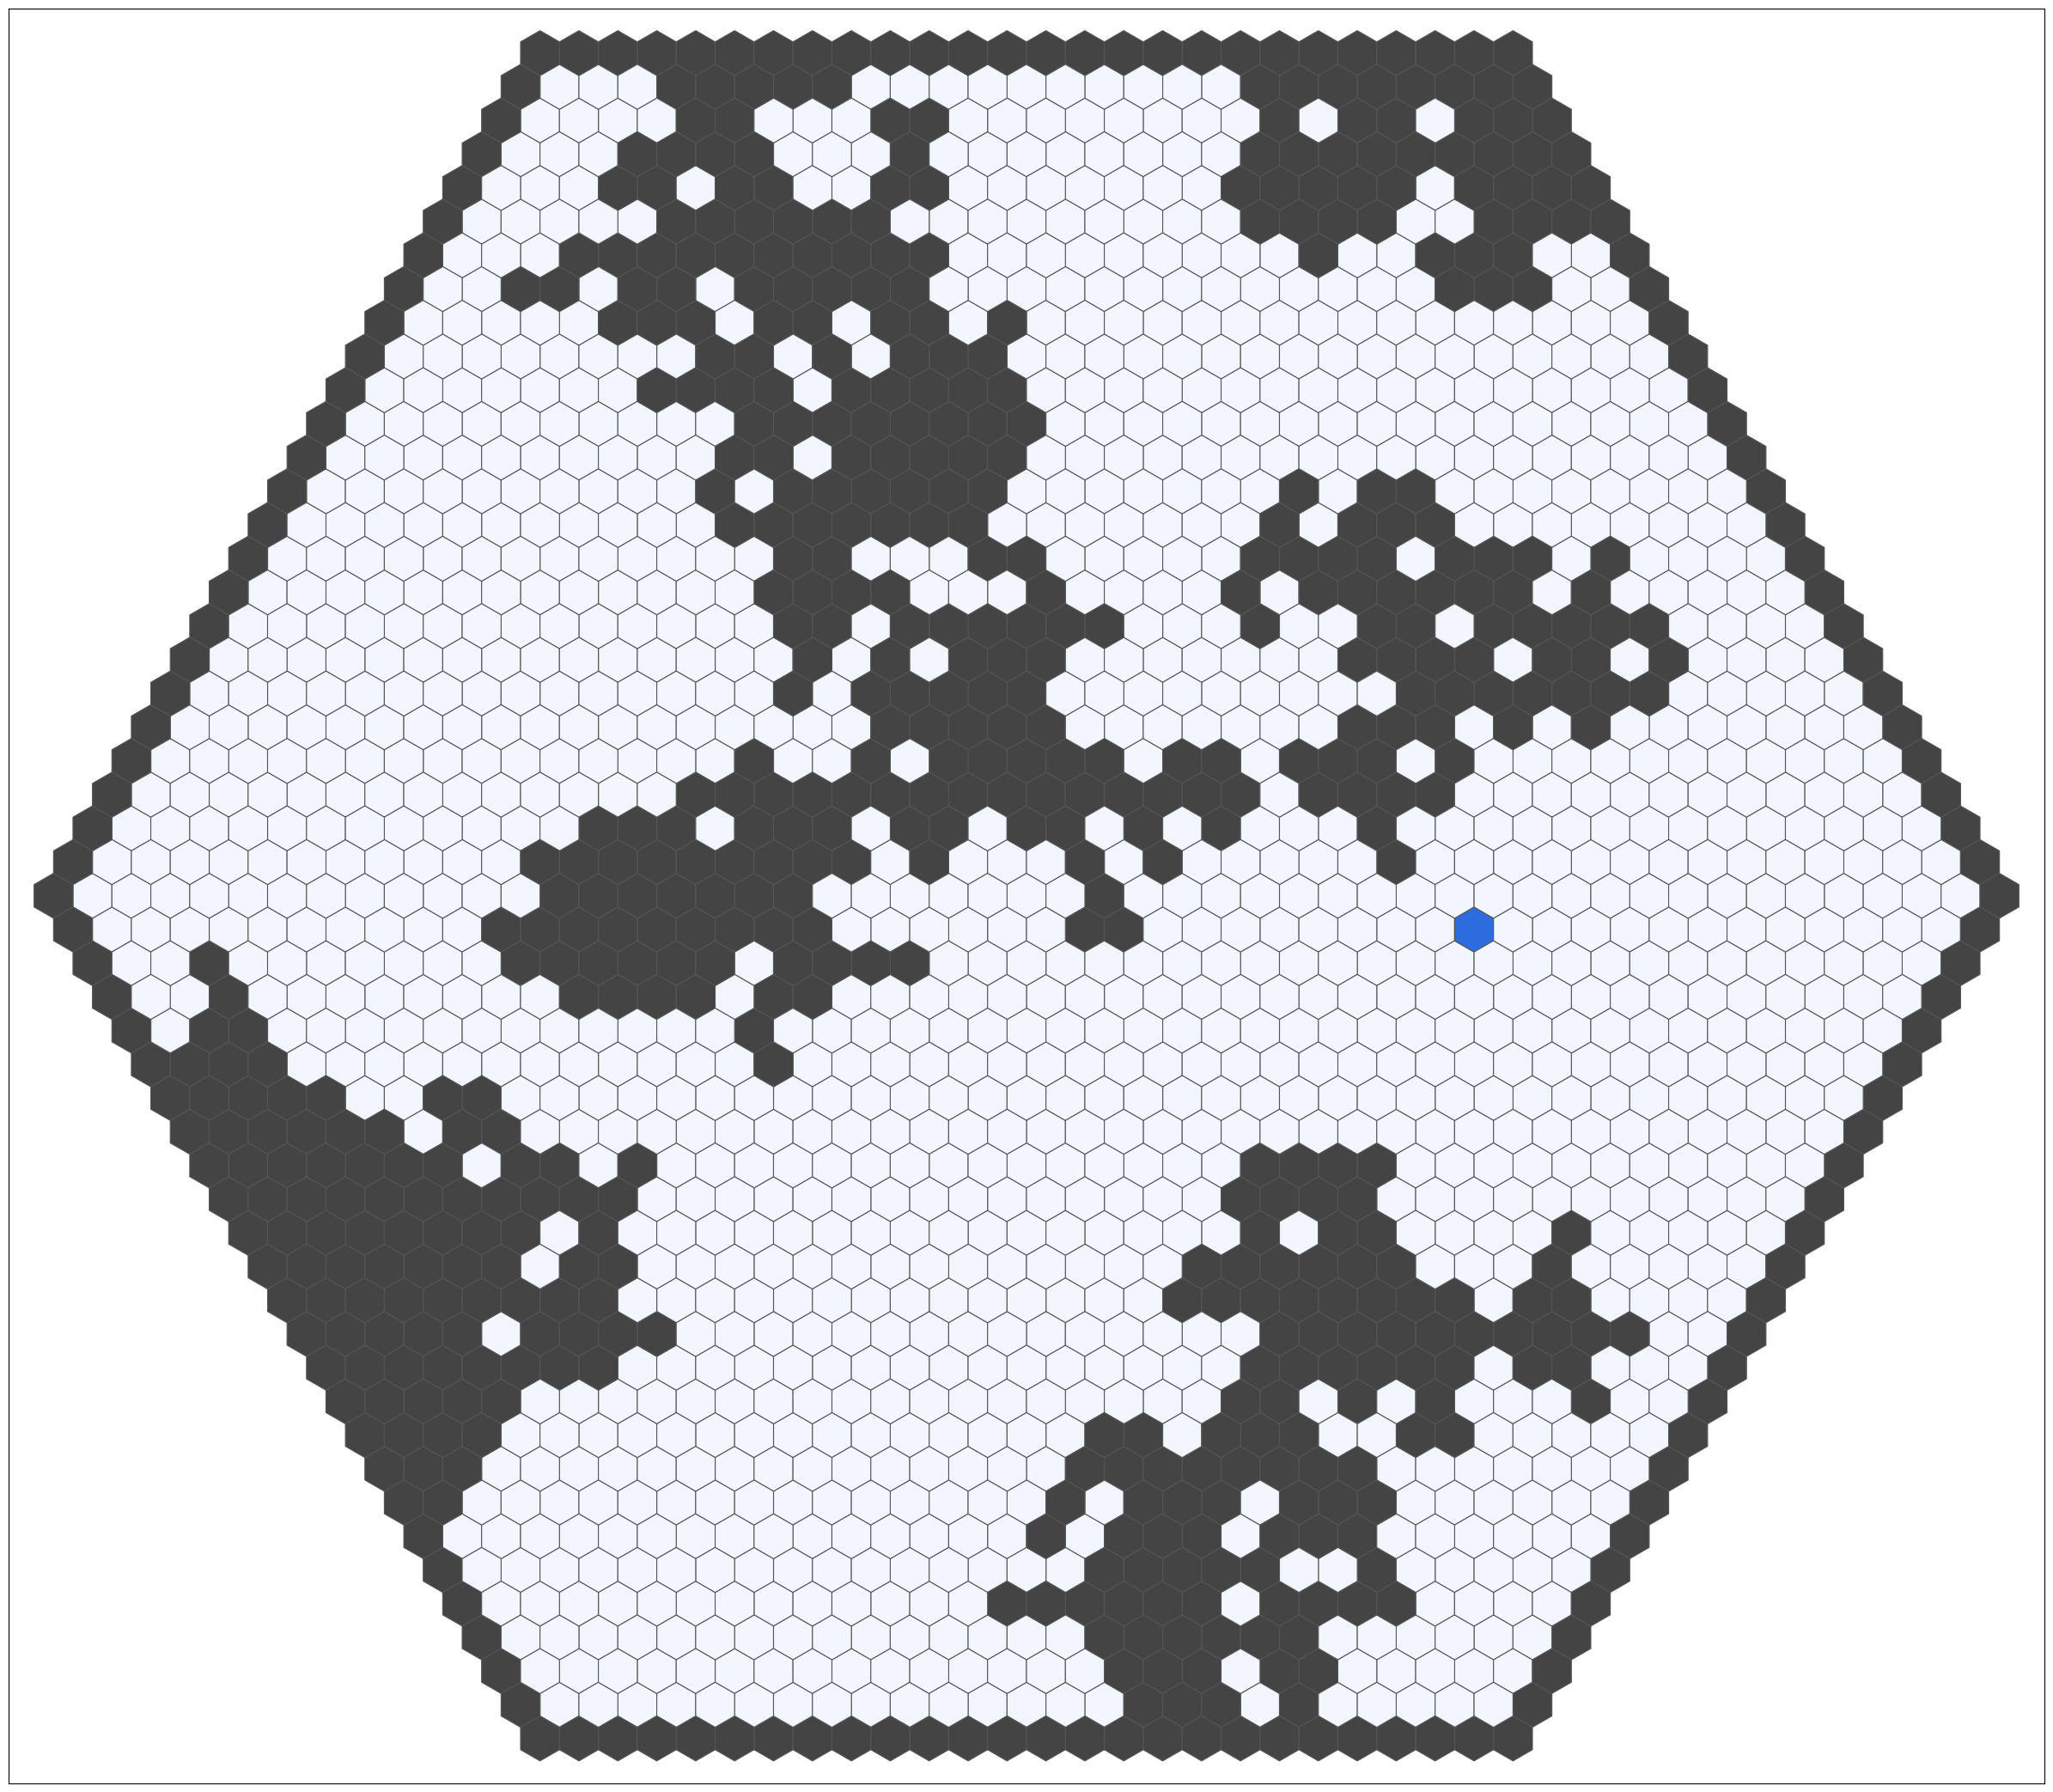

In [10]:
plot_hex_grid_2(
    obstacles=obstacles,
    start=goal,
    goal=goal,
    center=center,
    radius=radius,
    hex_size=hex_size,
    #path=predictions,
    #ax=ax,
    draw_axes=False,
    show_axis_legend=False,
    figsize=(24,24)
)

In [11]:
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def train_model(
    trainer,
    problem,
    search_callback=None,
    steps=10000,
    batch_size=64,
    search_every=100,
    search_when_exhausted=True,
    print_every=100,
    plot=True,
):
    losses = []

    progress = tqdm(
        range(steps),
        desc="Training",
        unit="step",
    )

    for step in progress:
    
        periodic_search = (
            search_callback is not None
            and search_every
            and step % search_every == 0
        )
    
        exhausted_search = (
            search_callback is not None
            and search_when_exhausted
            and not trainer.replay_buffer.has_training_batch(
                batch_size=batch_size,
                solution_weight=trainer.solution_weight,
                nonterminal_weight=trainer.nonterminal_weight,
            )
        )
    
        if periodic_search:
            search_callback()
        
        if (
            search_callback is not None
            and search_when_exhausted
        ):
            attempts = 0
            max_attempts = 20
            
            while (
                not trainer.replay_buffer.has_training_batch(
                    batch_size=batch_size,
                    solution_weight=trainer.solution_weight,
                    nonterminal_weight=trainer.nonterminal_weight,
                )
                and attempts < max_attempts
            ):
                search_callback()
                attempts += 1
    
        metrics = trainer.train_step(
            problem,
            batch_size=batch_size,
        )

        losses.append(metrics)

        progress.set_postfix(
            loss=f"{metrics['loss']:.4f}",
            solution_loss=f"{metrics['solution_loss']:.4f}",
            td_loss=f"{metrics['td_loss']:.4f}",
        )

        if print_every and step % print_every == 0:
            tqdm.write(
                f"{step}: {metrics} | "
                f"buffer={len(trainer.replay_buffer)}"
            )

    if plot:
        loss_values = [
            metrics["loss"]
            for metrics in losses
        ]

        plt.plot(loss_values)
        plt.xlabel("Training Step")
        plt.ylabel("MSE Loss")
        plt.title("TD Training Loss")
        plt.show()

    return losses


In [12]:
def collect_experience():

    environment_id = random.choice(
        list(environment_store.environments.keys())
    )

    hex_grid = environment_store.get(
        environment_id
    )

    start, goal = random_start_goal(
        center,
        radius,
        min_distance_ratio=0.5,
    )

    
    problem = HStarProblem(
        hex_grid,
        start,
        goal,
        a_max,  
        a_min,  
        start_v = start_v,
        goal_v = goal_v,
        collision_radius = 0,
        heuristic = lambda a,b:0,#h_cost_travel_time_euclidean,
        n_step = n_step,   
    )
    
    hs = BidHStarSearch(
        problem=problem,
        bidirectional=False,
        experience_collector=experience_collector,
        environment_id=environment_id,
    )

    solution_path = hs.search()

    # trainer.train_solution(
    #     solution_path,
    #     hex_grid,
    #     problem.goal,
    # )

In [13]:
# losses = train_model(
#     trainer,
#     problem,
#     search_callback=collect_experience,
#     steps=2000,
#     batch_size=16,
#     search_every=25,
#     print_every=50,
# )

In [14]:
losses = train_model(
    trainer,
    problem,
    search_callback=collect_experience,
    steps=1000,
    batch_size=64,
    #search_every=10,
    print_every=50,
)

Training:   0%|          | 0/1000 [00:00<?, ?step/s]

0: {'loss': 6.215493202209473, 'solution_loss': 8.819302558898926, 'td_loss': 0.04857705906033516, 'solution_samples': 45, 'nonterminal_samples': 19} | buffer=996352
50: {'loss': 0.8535935282707214, 'solution_loss': 1.116023302078247, 'td_loss': 0.23204949498176575, 'solution_samples': 45, 'nonterminal_samples': 19} | buffer=996352
100: {'loss': 0.582658052444458, 'solution_loss': 0.7095694541931152, 'td_loss': 0.28207850456237793, 'solution_samples': 45, 'nonterminal_samples': 19} | buffer=1023571
150: {'loss': 0.1932753473520279, 'solution_loss': 0.14553509652614594, 'td_loss': 0.30634433031082153, 'solution_samples': 45, 'nonterminal_samples': 19} | buffer=1023571
200: {'loss': 0.15076468884944916, 'solution_loss': 0.19514715671539307, 'td_loss': 0.04564833268523216, 'solution_samples': 45, 'nonterminal_samples': 19} | buffer=1051133
250: {'loss': 0.15563516318798065, 'solution_loss': 0.18746121227741241, 'td_loss': 0.08025767654180527, 'solution_samples': 45, 'nonterminal_samples':

KeyboardInterrupt: 

In [15]:
for sample in replay_buffer.sample(3):

    environment = environment_store.get(
        sample.environment_id
    )
    
    prediction = value_network.predict(
        problem=problem,
        state=sample.state,
        goal=sample.goal,
        environment=environment,
    )

    euclidian_h = travel_time_euclidean(
        sample.state.location, 
        sample.goal.location, 
        sample.state.velocity.magnitude, 
        problem.a_min, 
        problem.grid.hex_size
    )
    if sample.terminal:
        target = sample.cost
    else:
        next_prediction = value_network.predict(
            problem=problem,
            state=sample.next_state,
            goal=sample.goal,
            environment=environment,
        )
    
        target = sample.cost + next_prediction
    print("------------------------------------------------")
    print("State:", sample.state)
    print("Goal:", sample.goal)
    print("Environment:", sample.environment_id)
    print("Euclidian h:", euclidian_h)
    
    print("Predicted h:", prediction)
    print("TD target:", target)
    print("Difference:", prediction - target)
print("------------------------------------------------")


------------------------------------------------
State: RLState(location=HexCoord(q=12, r=-17), velocity=VelocityState(magnitude=15.79288815542991, direction=HexCoord(q=0, r=-1)))
Goal: RLState(location=HexCoord(q=11, r=8), velocity=VelocityState(magnitude=None, direction=None))
Environment: 16
Euclidian h: 2.4920458415022892
Predicted h: 1.6746679544448853
TD target: 1.8362241576541143
Difference: -0.16155620320922903
------------------------------------------------
State: RLState(location=HexCoord(q=12, r=-6), velocity=VelocityState(magnitude=12.06201756903818, direction=HexCoord(q=1, r=0)))
Goal: RLState(location=HexCoord(q=-8, r=-8), velocity=VelocityState(magnitude=None, direction=None))
Environment: 15
Euclidian h: 2.7192346850627676
Predicted h: 1.648501992225647
TD target: 1.8418406265607992
Difference: -0.1933386343351522
------------------------------------------------
State: RLState(location=HexCoord(q=-3, r=15), velocity=VelocityState(magnitude=18.236056455638227, direction

In [16]:
import torch

def plot_value_network_directions(
    value_network,
    problem,
    environment,
    goal,
    velocity: float,
    center,
    radius: int,
    hex_size: float = 1.0,
):
    """Plot predicted h across the map for the six primary hex directions."""

    directions = (
        HexCoord( 1,  0),  # E
        HexCoord( 1, -1),  # SE
        HexCoord( 0, -1),  # SW
        HexCoord(-1,  0),  # W
        HexCoord(-1,  1),  # NW
        HexCoord( 0,  1),  # NE
    )

    direction_names = (
        "E",
        "SE",
        "SW",
        "W",
        "NW",
        "NE",
    )

    value_network.eval()

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 12),
    )

    axes = axes.flatten()

    # Run the expensive spatial network only once.
    with torch.no_grad():
        value_map = value_network.value_map(
            environment,
            goal.location,
        )

    obstacles = set(environment.obstacles)

    for ax, direction, direction_name in zip(
        axes,
        directions,
        direction_names,
    ):
        predictions = {}

        # Find the ordinal index corresponding to this primary direction.
        direction_index = problem.DIRECTIONS.index(
            direction
        )

        for q in range(-radius, radius + 1):
            for r in range(-radius, radius + 1):

                location = HexCoord(
                    center.q + q,
                    center.r + r,
                )

                if hdist(center, location) > radius:
                    continue

                if location in obstacles:
                    continue

                state = RLState(
                    location=location,
                    velocity=VelocityState(
                        magnitude=velocity,
                        direction=direction_index,
                    ),
                )

                prediction = value_network.predict(
                    problem=problem,
                    state=state,
                    goal=goal,
                    environment=environment,
                    value_map=value_map,
                )

                predictions[location] = prediction

        plot_hex_grid_2(
            obstacles=obstacles,
            start=goal.location,
            goal=goal.location,
            center=center,
            radius=radius,
            hex_size=hex_size,
            path=predictions,
            ax=ax,
            draw_axes=False,
            show_axis_legend=False,
            plt_title=(
                f"{direction_name} "
                f"{direction} | "
                f"v={velocity:.2f}"
            ),
        )

    plt.tight_layout()
    plt.show()

In [17]:
def plot_value_network_directions(
    value_network,
    problem,
    environment,
    goal,
    velocity,
    center,
    radius,
    hex_size=1.0,
):
    value_network.eval()

    directions = (
        HexCoord( 1,  0),
        HexCoord( 1, -1),
        HexCoord( 0, -1),
        HexCoord(-1,  0),
        HexCoord(-1,  1),
        HexCoord( 0,  1),
    )

    direction_names = (
        "E",
        "SE",
        "SW",
        "W",
        "NW",
        "NE",
    )

    # Spatial context depends only on:
    # environment + goal
    #
    # So run HexUNet once.
    with torch.no_grad():
        context_map = value_network.encode_environment(
            environment,
            goal,
        )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 12),
    )

    axes = axes.flatten()

    obstacles = set(environment.obstacles)

    for ax, direction, direction_name in zip(
        axes,
        directions,
        direction_names,
    ):
        values = {}

        for q in range(
            center.q - radius,
            center.q + radius + 1,
        ):
            for r in range(
                center.r - radius,
                center.r + radius + 1,
            ):
                location = HexCoord(q, r)

                dq = q - center.q
                dr = r - center.r

                hex_distance = max(
                    abs(dq),
                    abs(dr),
                    abs(dq + dr),
                )

                if hex_distance > radius:
                    continue

                if location in obstacles:
                    continue

                state = RLState(
                    location=location,
                    velocity=VelocityState(
                        magnitude=velocity,
                        direction=direction,
                    ),
                )

                with torch.no_grad():
                    value = value_network.value(
                        problem=problem,
                        state=state,
                        goal=goal,
                        environment=environment,
                        context_map=context_map,
                    )

                values[location] = value.item()

        plot_hex_grid_2(
            obstacles=obstacles,
            path=values,
            start=problem.start,
            center=center,
            radius=radius,
            hex_size=hex_size,
            ax=ax,
        )

        ax.set_title(
            f"{direction_name}: {direction}"
        )

    plt.tight_layout()
    plt.show()

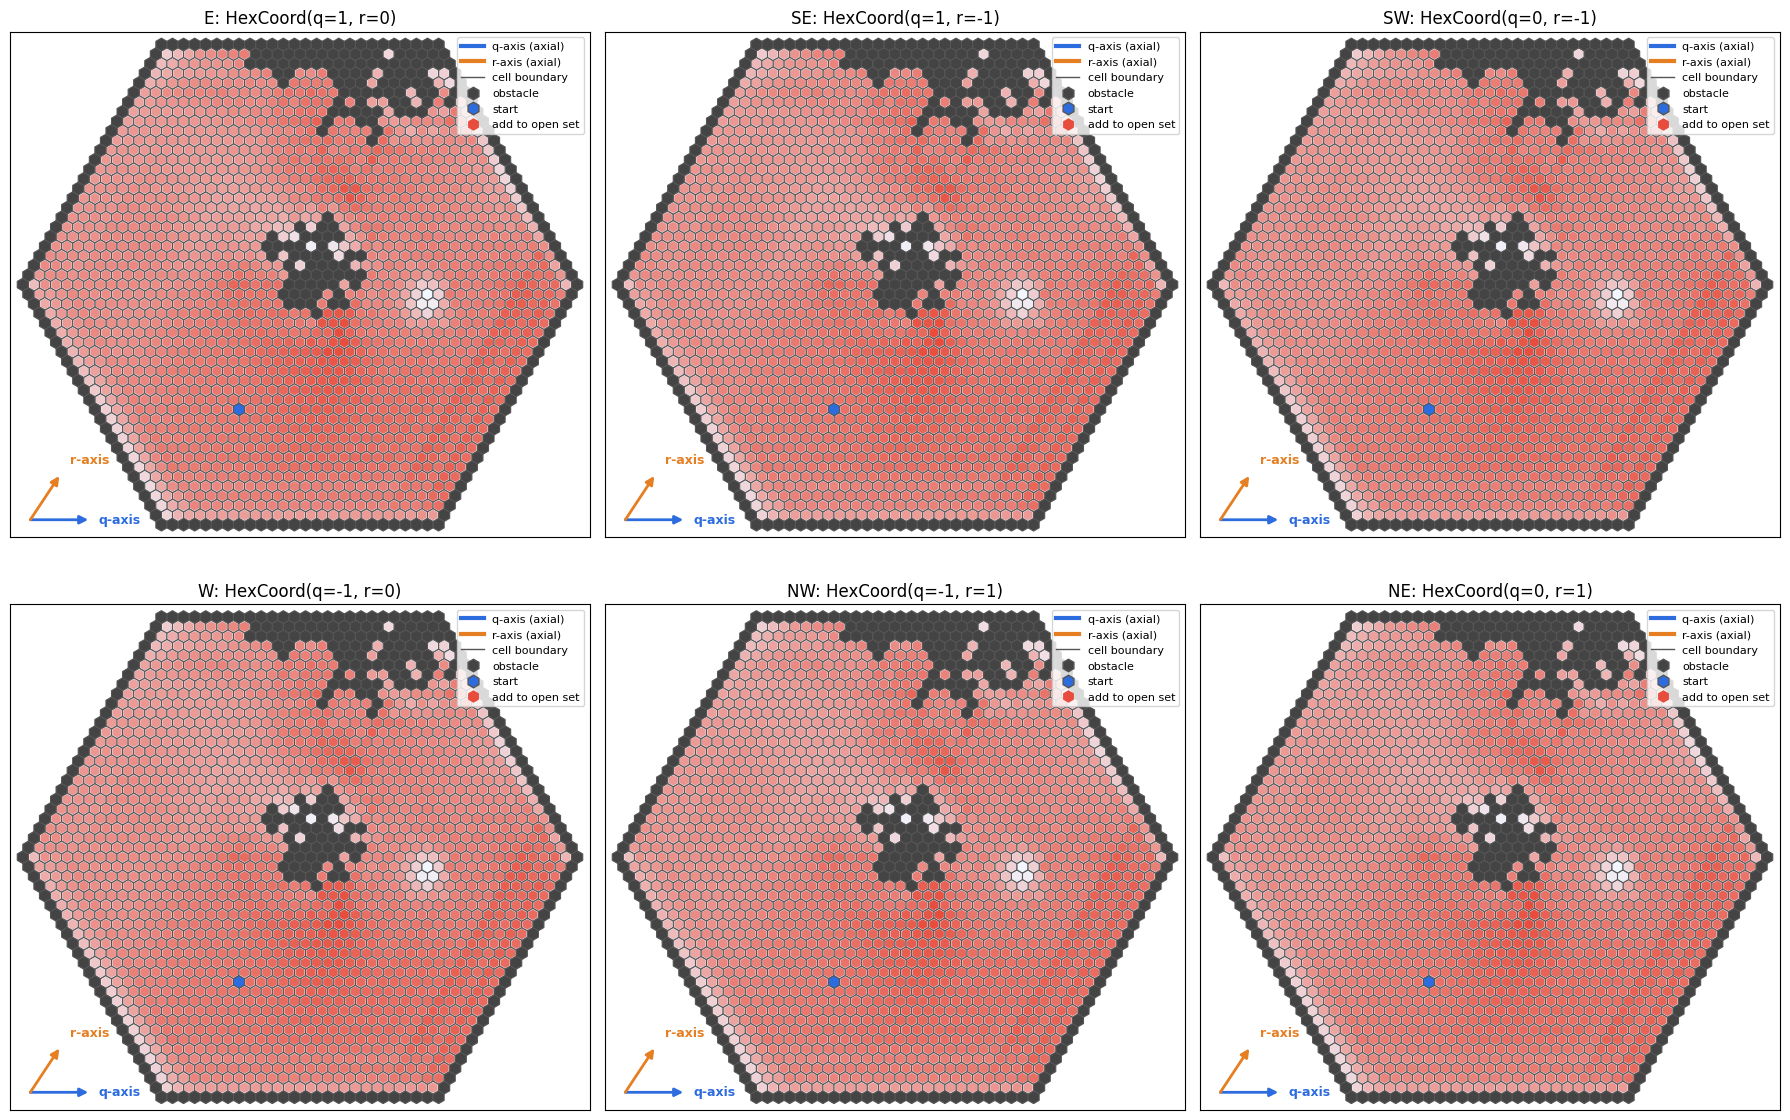

In [31]:
s = replay_buffer.sample(100)[2]

goal = RLState(
    location=problem.goal,
    velocity=problem.goal_v,
)

plot_value_network_directions(
    value_network,
    problem,
    environment_store.get(s.environment_id),
    goal=goal,
    velocity=2,
    center=center,
    radius=radius,
    hex_size=hex_size,
)

In [19]:
def get_value_network_directions(
    value_network,
    problem,
    environment,
    goal,
    location,
    velocity,
):
    """
    Return predicted h = V(s) at one hex for the six primary
    hex directions, holding location and velocity constant.
    """

    directions = {
        "E":  HexCoord( 1,  0),
        "SE": HexCoord( 1, -1),
        "SW": HexCoord( 0, -1),
        "W":  HexCoord(-1,  0),
        "NW": HexCoord(-1,  1),
        "NE": HexCoord( 0,  1),
    }

    value_network.eval()

    with torch.no_grad():

        context_map = value_network.encode_environment(
            environment,
            goal,
        )

        values = {}

        for name, direction in directions.items():

            state = RLState(
                location=location,
                velocity=VelocityState(
                    magnitude=velocity,
                    direction=direction,
                ),
            )

            value = value_network.value(
                problem=problem,
                state=state,
                goal=goal,
                environment=environment,
                context_map=context_map,
            )

            values[name] = value.item()

    return values

In [30]:
values = get_value_network_directions(
    value_network=value_network,
    problem=problem,
    environment=environment_store.get(
        s.environment_id
    ),
    goal=goal,
    location=HexCoord(5, -4),
    velocity=2,
)

print(values)

{'E': 5.254047393798828, 'SE': 5.317112445831299, 'SW': 5.238882064819336, 'W': 5.146808624267578, 'NW': 5.067796230316162, 'NE': 5.092473030090332}


In [21]:
def direction_sensitivity(
    value_network,
    problem,
    environment,
    goal,
    location,
    velocity,
    directions,
):
    with torch.no_grad():
        context_map = value_network.encode_environment(
            environment,
            goal,
        )

    values = []

    for direction in directions:
        state = RLState(
            location=location,
            velocity=VelocityState(
                magnitude=velocity,
                direction=direction,
            ),
        )

        value = value_network.predict(
            problem=problem,
            state=state,
            goal=goal,
            environment=environment,
            context_map=context_map,
        )

        values.append(value)

    return values

In [22]:
samples = replay_buffer.sample_solution(10)

for sample in samples:
    print(
        sample.state.location,
        sample.state.velocity.magnitude,
        sample.state.velocity.direction,
    )

HexCoord(q=2, r=6) 15.120539229772588 HexCoord(q=-1, r=1)
HexCoord(q=-23, r=13) 11.623250964784873 HexCoord(q=0, r=1)
HexCoord(q=-5, r=14) 7.896444077714955 HexCoord(q=1, r=-1)
HexCoord(q=-9, r=20) 0 None
HexCoord(q=-24, r=14) 19.87228180470738 HexCoord(q=-1, r=1)
HexCoord(q=5, r=-12) 6.964009090454188 HexCoord(q=0, r=-1)
HexCoord(q=-6, r=20) 0 None
HexCoord(q=6, r=1) 4.559014113909555 HexCoord(q=0, r=1)
HexCoord(q=7, r=2) 13.677042341728667 HexCoord(q=1, r=-1)
HexCoord(q=9, r=-5) 11.623250964784871 HexCoord(q=0, r=-1)


In [23]:
sample = replay_buffer.sample_solution(1)[0]

print("state:")
print(sample.state)

print("\nencoded:")
print(
    value_network.encode_state(
        sample.state,
        sample.goal,
        environment,
    )
)

state:
RLState(location=HexCoord(q=-22, r=9), velocity=VelocityState(magnitude=10.194265469082737, direction=HexCoord(q=0, r=-1)))

encoded:
tensor([-0.1200,  0.3600, 10.1943,  0.0000, -1.0000])


In [24]:
location = HexCoord(-20, 9)
speed = 10.0

directions = [
    HexCoord(1, 0),
    HexCoord(1, -1),
    HexCoord(0, -1),
    HexCoord(-1, 0),
    HexCoord(-1, 1),
    HexCoord(0, 1),
]

for direction in directions:

    state = RLState(
        location=location,
        velocity=VelocityState(
            magnitude=speed,
            direction=direction,
        ),
    )

    encoded = value_network.encode_state(
        state,
        goal,
        environment,
    )

    print(
        direction,
        encoded.tolist(),
    )

HexCoord(q=1, r=0) [-1.2799999713897705, 0.4000000059604645, 10.0, 1.0, 0.0]
HexCoord(q=1, r=-1) [-1.2799999713897705, 0.4000000059604645, 10.0, 1.0, -1.0]
HexCoord(q=0, r=-1) [-1.2799999713897705, 0.4000000059604645, 10.0, 0.0, -1.0]
HexCoord(q=-1, r=0) [-1.2799999713897705, 0.4000000059604645, 10.0, -1.0, 0.0]
HexCoord(q=-1, r=1) [-1.2799999713897705, 0.4000000059604645, 10.0, -1.0, 1.0]
HexCoord(q=0, r=1) [-1.2799999713897705, 0.4000000059604645, 10.0, 0.0, 1.0]


In [25]:
with torch.no_grad():
    context_map = value_network.encode_environment(
        environment,
        goal,
    )


In [26]:
for direction in directions:

    state = RLState(
        location=location,
        velocity=VelocityState(
            magnitude=speed,
            direction=direction,
        ),
    )

    state_features = value_network.encode_state(
        state,
        goal,
        environment,
    )

    value = value_network.predict(
        problem=problem,
        state=state,
        goal=goal,
        environment=environment,
        context_map=context_map,
    )

    print(
        direction,
        state_features.tolist(),
        f"V={value:.6f}",
    )

HexCoord(q=1, r=0) [-1.2799999713897705, 0.4000000059604645, 10.0, 1.0, 0.0] V=1.886362
HexCoord(q=1, r=-1) [-1.2799999713897705, 0.4000000059604645, 10.0, 1.0, -1.0] V=1.998416
HexCoord(q=0, r=-1) [-1.2799999713897705, 0.4000000059604645, 10.0, 0.0, -1.0] V=2.006444
HexCoord(q=-1, r=0) [-1.2799999713897705, 0.4000000059604645, 10.0, -1.0, 0.0] V=1.951289
HexCoord(q=-1, r=1) [-1.2799999713897705, 0.4000000059604645, 10.0, -1.0, 1.0] V=1.908685
HexCoord(q=0, r=1) [-1.2799999713897705, 0.4000000059604645, 10.0, 0.0, 1.0] V=1.844052


In [27]:
from collections import Counter

def solution_direction_counts(
    replay_buffer,
):
    samples = replay_buffer.sample_solution(
        replay_buffer.solution_size
    )

    counts = Counter()

    for sample in samples:
        direction = sample.state.velocity.direction

        key = (
            None
            if direction is None
            else (direction.q, direction.r)
        )

        counts[key] += 1

    return counts